(mmm_funnel_joint_vs_two_stage)=
# Joint or Two-Stage? Estimating a Brand Funnel Through Branded Search

Brand advertising such as video reaches sales by two routes:

- some people convert soon after seeing an ad;
- others become interested in the brand, search for it (often interacting with paid media), and convert later.

A funnel-aware MMM, like the one in {ref}`mmm_funnel_mueffect`, models both routes, so it can tell how much of a brand campaign's effect arrives through brand demand.

Such a model has two equations: one for how advertising moves brand demand, and one for how demand and media move sales. There are two ways to estimate them:

- Two-stage: fit the demand equation on branded queries first, then fit the sales equation with a demand series as an input, and chain the two.
- One-stage (joint): fit both equations together, as one model with a likelihood for branded queries and one for sales.

To compare them, we simulate data where the true effects are known and give both strategies the same model specification, so any difference comes from how the model is estimated. The comparison builds up in three layers:

1. branded queries are an exact measure of brand demand (a hypothetical scenario);
2. branded queries are a noisy proxy for brand demand;
3. on top of that, the sales equation misses a driver, a temporary price cut.

Results showed that:

- **In a perfect world** in which branded queries are a perfect measure of brand demand, the two strategies give the same answers and recommend the same budget, so fitting jointly adds nothing.
- **When branded queries are a noisy proxy** for brand demand, the joint model outperforms two-stage. It is more accurate on every effect, its intervals are close to calibrated where the two-stage intervals are too narrow, and its budget advice loses fewer conversions. A common shortcut, feeding the raw queries into the sales equation, understates how much of a campaign's effect arrives through demand. Estimating demand, in either strategy, removes most of that bias.
- **When the sales equation misses a driver**, the joint model's budget advice still holds up better, but its estimate of demand absorbs part of the missing driver, and neither strategy splits video's effect between its two paths reliably.
- **The budget optimizer needs the whole path** from brand media through demand to sales. A joint model has it built in. With two-stage, it has to be added by hand; without it, the plan lost 28% of the conversions that media drive.

The joint model is the better choice, then, but only when the model is well specified.

## Prepare Notebook

In [1]:
import logging
import warnings
from typing import Any, Literal

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pymc.dims as pmd
import pytensor
import pytensor.tensor as pt
import pytensor.xtensor as ptx
import xarray as xr
from pydantic import InstanceOf
from pytensor.compile.mode import Mode
from scipy import stats
from scipy.interpolate import BSpline

from pymc_marketing.mmm import (
    AdstockTransformation,
    GeometricAdstock,
    LogisticSaturation,
    SaturationTransformation,
)
from pymc_marketing.mmm.additive_effect import DataVarMuEffect, IncrementalitySpec
from pymc_marketing.mmm.budget_optimizer import BudgetOptimizer
from pymc_marketing.mmm.data_conversion import to_mmm_dataset
from pymc_marketing.mmm.mmm import MMM
from pymc_marketing.mmm.transformers import geometric_adstock, logistic_saturation
from pymc_marketing.serialization import serialization

warnings.filterwarnings("ignore", category=FutureWarning)
# The notebook fits a few hundred models; keep the sampler's log lines out of the output.
logging.getLogger("pymc").setLevel(logging.ERROR)

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%config InlineBackend.figure_format = "retina"

In [2]:
seed: int = sum(map(ord, "joint funnel"))


def rng_for(*key: int) -> np.random.Generator:
    """Return an independent random stream for one part of the notebook.

    Each world and each set of fits draws from its own stream, keyed by layer and
    replication, so rerunning a cell reproduces its results whatever ran before.
    """
    return np.random.default_rng([seed, *key])


N_WEEKS = 156
L_MAX = 8
CHANNELS = ["video", "search", "display"]

## The funnel

The data follow the causal structure in the diagram below.

- Upper-funnel media raise brand demand, and brand demand drives conversions. For upper-funnel media, demand is a **mediator**: part of their effect travels through it.
- Organic interest moves brand demand too.
- Branded queries measure brand demand. They rise and fall with it but do not cause conversions.
- Performance channels such as search and display follow brand demand: search ads show on branded searches, and display spend grows with the audiences built from people who search. Demand moves both their spend and conversions, so it is a **confounder** for these channels.

A standard MMM with a single equation cannot handle both roles. Leaving demand out over-credits search and display, which get the credit for demand they only follow. Adding branded queries as an ordinary input blocks the path through demand and under-credits upper-funnel media. Modeling the demand and sales equations explicitly fixes both, at the cost of estimating more effects. In the simulation below, the upper-funnel channel is video.

In [3]:
def draw_dag(ax, nodes, edges, title=None):
    """Draw a causal diagram: observed nodes in gray, latent nodes in white."""
    artists = {}
    for name, (x, y, label, observed) in nodes.items():
        artists[name] = ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            fontsize=12,
            bbox={
                "boxstyle": "round,pad=0.4",
                "facecolor": "#d9d9d9" if observed else "white",
                "edgecolor": "black",
            },
        )
    for start, end, style, rad in edges:
        ax.annotate(
            "",
            xy=(0.5, 0.5),
            xycoords=artists[end],
            xytext=(0.5, 0.5),
            textcoords=artists[start],
            arrowprops={
                "arrowstyle": "-|>",
                "linestyle": style,
                "linewidth": 1.3,
                "color": "black",
                "patchA": artists[start].get_bbox_patch(),
                "patchB": artists[end].get_bbox_patch(),
                "shrinkA": 2,
                "shrinkB": 2,
                "connectionstyle": f"arc3,rad={rad}",
            },
        )
    if title:
        ax.set_title(title)
    ax.axis("off")


def frame_box(ax, x0, y0, x1, y1, label):
    """Dashed frame marking which data a fit sees."""
    ax.add_patch(
        plt.Rectangle(
            (x0, y0), x1 - x0, y1 - y0, fill=False, linestyle="--", color="#52514e"
        )
    )
    ax.text(x0 + 0.08, y1 - 0.08, label, va="top", fontsize=11, color="#52514e")

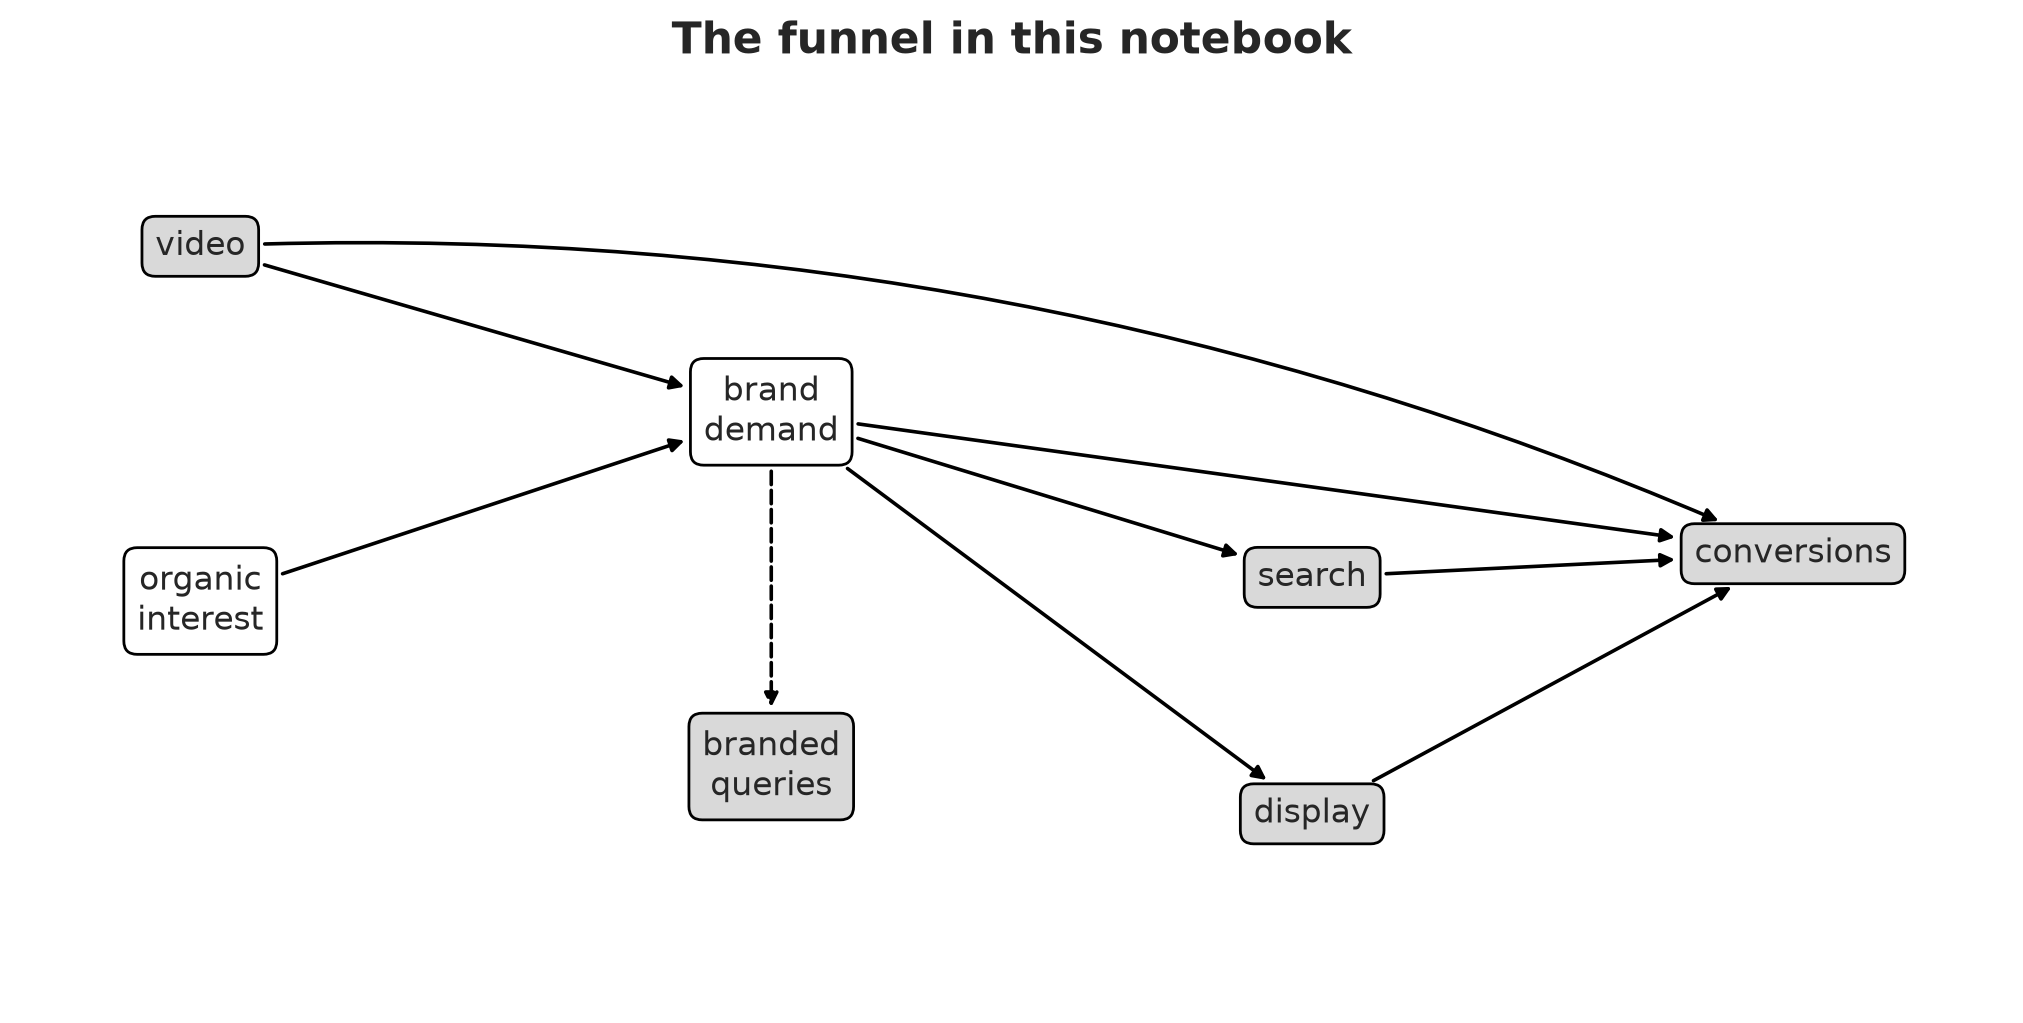

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
draw_dag(
    ax,
    nodes={
        "video": (0.0, 2.6, "video", True),
        "organic": (0.0, 1.1, "organic\ninterest", False),
        "demand": (1.9, 1.9, "brand\ndemand", False),
        "queries": (1.9, 0.4, "branded\nqueries", True),
        "search": (3.7, 1.2, "search", True),
        "display": (3.7, 0.2, "display", True),
        "conversions": (5.3, 1.3, "conversions", True),
    },
    edges=[
        ("video", "demand", "-", 0),
        ("organic", "demand", "-", 0),
        ("demand", "queries", "--", 0),
        ("video", "conversions", "-", -0.12),
        ("demand", "conversions", "-", 0),
        ("demand", "search", "-", 0),
        ("demand", "display", "-", 0),
        ("search", "conversions", "-", 0),
        ("display", "conversions", "-", 0),
    ],
)
ax.set(xlim=(-0.6, 6.0), ylim=(-0.6, 3.3))
fig.suptitle("The funnel in this notebook", fontsize=16, fontweight="bold");

**Caption:** The funnel used throughout the notebook. Gray boxes are observed in the data; white boxes are latent. The dashed arrow is a measurement: branded queries read brand demand.

## One-stage and two-stage estimation

Both strategies use the same two equations:

- the **demand equation**: brand demand = baseline + video's lift (adstock and saturation) + smooth organic interest, measured by branded queries;
- the **sales equation**: conversions = intercept + effect of each channel + effect of brand demand.

Two-stage fits the demand equation on branded queries first (stage 1), then the sales equation with a demand series as a fixed input (stage 2). Video's effect through demand is stage 1's lift times stage 2's effect of demand. Pairing posterior draw $i$ of stage 1 with draw $i$ of stage 2 carries stage 1's uncertainty into that product. Each stage is a small model you can fit and check on its own, which is how {ref}`mmm_intro_upper_funnel` and {ref}`mmm_upper_funnel_causal_approach` approach the same problem.

The joint model puts both equations and their likelihoods into one model and fits them at once. Conversions can then inform the demand equation, and the posterior keeps track of how the parameters of the two equations depend on each other.

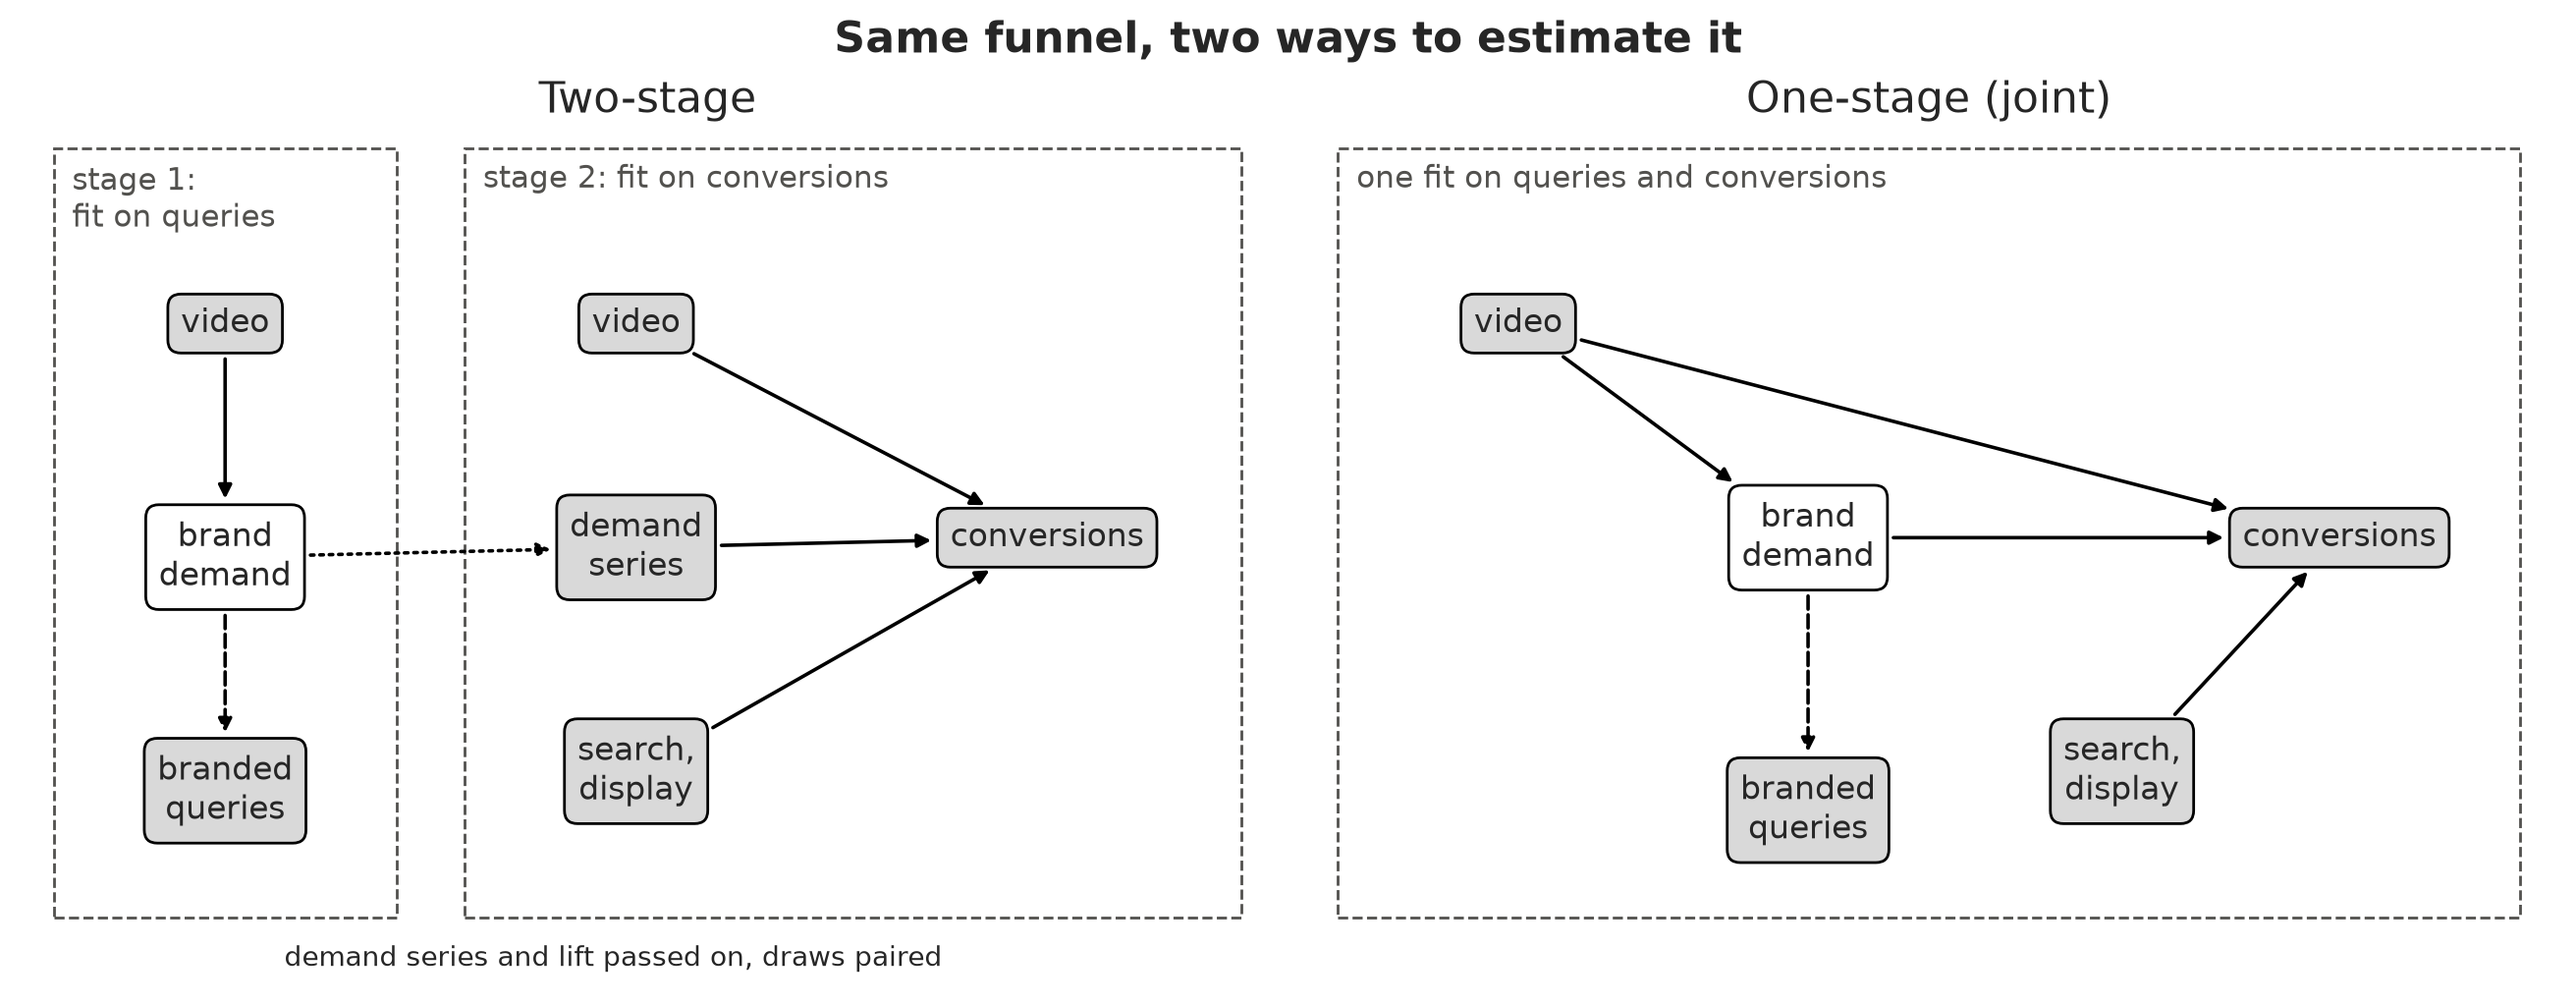

In [5]:
fig, (ax_two, ax_one) = plt.subplots(1, 2, figsize=(13, 5))

draw_dag(
    ax_two,
    nodes={
        "video1": (0.3, 2.3, "video", True),
        "demand1": (0.3, 1.1, "brand\ndemand", False),
        "queries1": (0.3, -0.1, "branded\nqueries", True),
        "video2": (2.1, 2.3, "video", True),
        "others2": (2.1, 0.0, "search,\ndisplay", True),
        "series2": (2.1, 1.15, "demand\nseries", True),
        "conversions2": (3.9, 1.2, "conversions", True),
    },
    edges=[
        ("video1", "demand1", "-", 0),
        ("demand1", "queries1", "--", 0),
        ("video2", "conversions2", "-", 0),
        ("others2", "conversions2", "-", 0),
        ("series2", "conversions2", "-", 0),
        ("demand1", "series2", ":", 0),
    ],
    title="Two-stage",
)
frame_box(ax_two, -0.45, -0.75, 1.05, 3.2, "stage 1:\nfit on queries")
frame_box(ax_two, 1.35, -0.75, 4.75, 3.2, "stage 2: fit on conversions")
ax_two.set(xlim=(-0.6, 4.9), ylim=(-1.1, 3.3))
ax_two.text(2.0, -1.0, "demand series and lift passed on, draws paired", ha="center")

draw_dag(
    ax_one,
    nodes={
        "video": (0.3, 2.3, "video", True),
        "demand": (1.5, 1.2, "brand\ndemand", False),
        "queries": (1.5, -0.2, "branded\nqueries", True),
        "others": (2.8, 0.0, "search,\ndisplay", True),
        "conversions": (3.7, 1.2, "conversions", True),
    },
    edges=[
        ("video", "demand", "-", 0),
        ("demand", "queries", "--", 0),
        ("video", "conversions", "-", 0),
        ("demand", "conversions", "-", 0),
        ("others", "conversions", "-", 0),
    ],
    title="One-stage (joint)",
)
frame_box(ax_one, -0.45, -0.75, 4.45, 3.2, "one fit on queries and conversions")
ax_one.set(xlim=(-0.6, 4.6), ylim=(-1.1, 3.3))
fig.suptitle("Same funnel, two ways to estimate it", fontsize=16, fontweight="bold");

**Caption:** In the two-stage fit (left), stage 1 never sees conversions and stage 2 treats its demand series as known. In the joint fit (right), branded queries and conversions are both likelihoods of one model.

## When can the two differ?

Write $\theta_1$ for the parameters of the demand equation and $\theta_2$ for those of the sales equation. With branded queries $Q$ and conversions $Y$, the joint posterior is

$$
p(\theta_1, \theta_2 \mid Q, Y) \;\propto\; p(Q \mid \theta_1)\; p(Y \mid \theta_1, \theta_2, Q)\; p(\theta_1)\, p(\theta_2).
$$

If branded queries measure demand exactly, the sales equation can use the observed series $Q$ itself. Conversions then do not depend on $\theta_1$, and the posterior splits into two independent pieces:

$$
p(\theta_1, \theta_2 \mid Q, Y) = p(\theta_1 \mid Q)\; p(\theta_2 \mid Y, Q).
$$

That is exactly what the two-stage strategy estimates, so both strategies give the same answer.

Real branded queries measure demand with noise: some people in the market never search, some search for other reasons, and query data often come from sampled or rounded sources. The sales equation then needs the model's estimate of demand, which depends on $\theta_1$, and conversions carry information about the demand equation. The joint model uses that information, while stage 1 of the two-stage strategy never sees conversions. The layers below measure how much that matters.

## Data generating process

We simulate three years of weekly data for one market. The code below defines the transformations and a function that draws a whole synthetic world from fixed true parameters. Every model in the notebook uses the same adstock and logistic saturation families as the simulation. The sales equation uses PyMC-Marketing's default priors; the priors of the demand equation are set in the model code below.

In [6]:
# The simulation uses the library's transforms, compiled once so the loops below call them
# as plain NumPy functions.
_x, _alpha = pt.matrix("x"), pt.vector("alpha")
_adstock = pytensor.function(
    [_x, _alpha],
    geometric_adstock(
        ptx.as_xtensor(_x, dims=("row", "date")),
        alpha=ptx.as_xtensor(_alpha, dims=("row",)),
        l_max=L_MAX,
        normalize=True,
        dim="date",
    )
    .transpose("row", "date")
    .values,
)
_s, _lam = pt.vector("x"), pt.vector("lam")
_saturate = pytensor.function(
    [_s, _lam],
    logistic_saturation(
        ptx.as_xtensor(_s, dims=("i",)), lam=ptx.as_xtensor(_lam, dims=("i",))
    ).values,
)


def adstock(x, alpha):
    """Apply normalized geometric adstock, one row per value of ``alpha``."""
    alpha = np.atleast_1d(np.asarray(alpha, dtype=float))
    x = np.broadcast_to(np.asarray(x, dtype=float), (alpha.size, np.shape(x)[-1]))
    return _adstock(x, alpha)


def saturate(x, lam):
    """Apply the logistic saturation curve (without its scale ``beta``)."""
    x, lam = np.broadcast_arrays(
        np.asarray(x, dtype=float), np.asarray(lam, dtype=float)
    )
    return _saturate(x.ravel(), lam.ravel()).reshape(x.shape)


def spline_basis(n_weeks=N_WEEKS, n_knots=12, degree=3):
    """Cubic B-spline basis over the weeks, one centered column per basis function.

    Twelve knots give 14 basis functions. Centering each column keeps the spline's
    mean at zero, so the baseline alone sets the level of demand.
    """
    t = np.linspace(0, 1, n_weeks)
    inner = np.linspace(0, 1, n_knots)
    knots = np.concatenate([[0] * degree, inner, [1] * degree])
    basis = BSpline.design_matrix(t, knots, degree).toarray()
    return basis - basis.mean(axis=0)

In [7]:
true = {
    # demand equation: video -> brand demand
    "query_baseline": 0.5,
    "adstock_hub_alpha": 0.5,
    "sat_hub_lam": 4.0,
    "sat_hub_beta": 0.6,
    # conversions
    "intercept": 1.0,
    "video_alpha": 0.4,
    "video_lam": 2.0,
    "video_beta": 0.25,
    "query_alpha": 0.3,
    "query_coef": 0.5,
    "search_alpha": 0.2,
    "search_lam": 2.0,
    "search_beta": 0.45,
    "display_alpha": 0.3,
    "display_lam": 2.5,
    "display_beta": 0.3,
    "sigma": 0.04,
}


def simulate_world(rng):
    """Simulate one synthetic world: spend, brand demand, conversions, and true effects."""
    dates = pd.date_range("2023-01-02", periods=N_WEEKS, freq="W-MON")

    # Video runs in flights of 3 to 6 weeks, with little spend in between.
    video = rng.uniform(0, 4, N_WEEKS)
    week = 0
    while week < N_WEEKS:
        week += rng.integers(3, 9)
        length = rng.integers(3, 7)
        video[week : week + length] = rng.uniform(40, 90)
        week += length

    # Brand demand: baseline + video lift + smooth organic interest + weekly shocks.
    basis = spline_basis()
    organic = basis @ rng.normal(0, 0.18, basis.shape[1])
    lift = true["sat_hub_beta"] * saturate(
        adstock(video / video.max(), true["adstock_hub_alpha"])[0], true["sat_hub_lam"]
    )
    demand = true["query_baseline"] + lift + organic + rng.normal(0, 0.03, N_WEEKS)

    # Performance spend follows brand demand, plus budget changes of its own.
    def budget_changes(scale):
        e = np.zeros(N_WEEKS)
        for i in range(1, N_WEEKS):
            e[i] = 0.7 * e[i - 1] + rng.normal(0, scale)
        return e

    search = np.clip(5 + 45 * demand + budget_changes(7), 1, None)
    display = np.clip(3 + 18 * demand + budget_changes(5), 1, None)
    spend = {"video": video, "search": search, "display": display}

    media = {
        c: true[f"{c}_beta"]
        * saturate(
            adstock(spend[c] / spend[c].max(), true[f"{c}_alpha"])[0], true[f"{c}_lam"]
        )
        for c in CHANNELS
    }
    demand_path = true["query_coef"] * adstock(demand, true["query_alpha"])[0]
    conversions = (
        true["intercept"]
        + sum(media.values())
        + demand_path
        + rng.normal(0, true["sigma"], N_WEEKS)
    )
    indirect = true["query_coef"] * adstock(lift, true["query_alpha"])[0]
    world = pd.DataFrame(
        {
            "date": dates,
            **spend,
            "conversions": conversions,
            "demand_true": demand,
            "organic_true": organic,
        }
    )
    effects_true = {
        "video_direct": media["video"],
        "video_indirect": indirect,
        "video_total": media["video"] + indirect,
        "search": media["search"],
        "display": media["display"],
    }
    return world, effects_true


def measure_queries(world, sigma, rng):
    """Observed branded query volume: brand demand plus measurement noise."""
    observed = world["demand_true"] + rng.normal(0, sigma, len(world))
    return world.assign(branded_queries=observed)

Here is one world. The replication studies later draw many more, all with the same true parameters: they differ in their video flights, organic interest, budget changes, and noise.

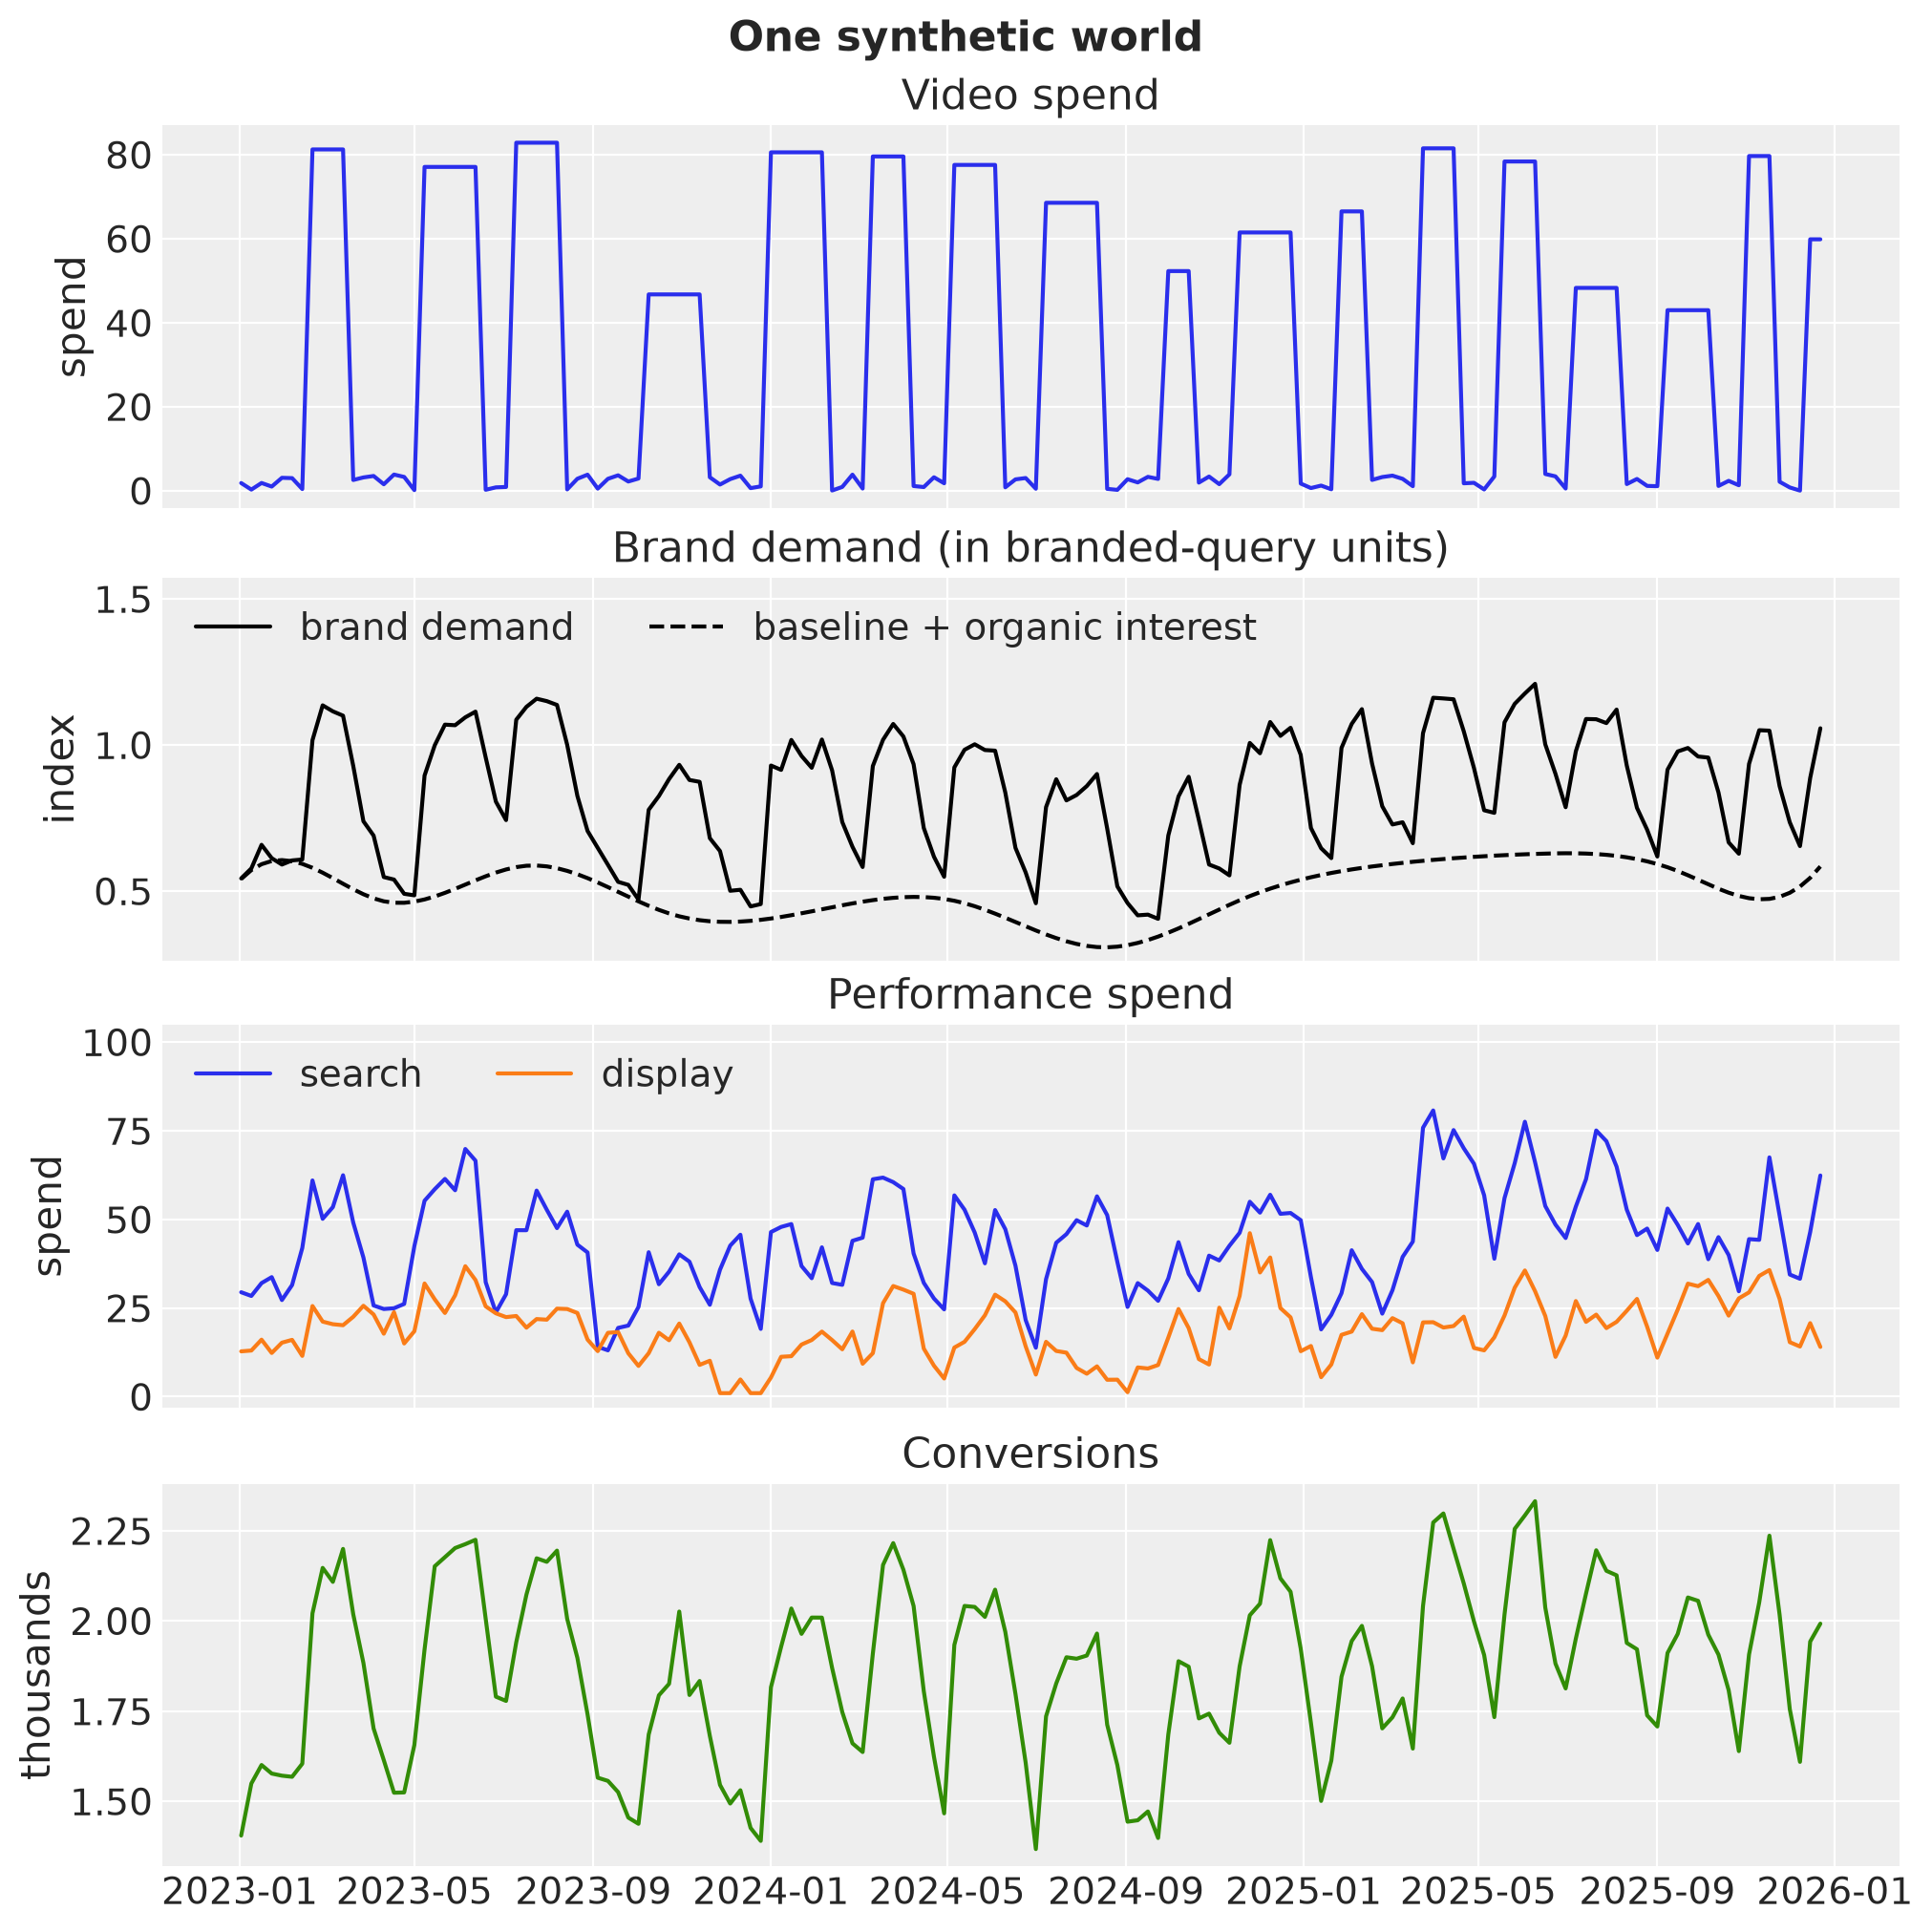

In [8]:
world, truth = simulate_world(rng_for(0))
basis = spline_basis()

fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True, layout="constrained")
axes[0].plot(world["date"], world["video"], color="C0")
axes[0].set(title="Video spend", ylabel="spend")
axes[1].plot(world["date"], world["demand_true"], color="black", label="brand demand")
axes[1].plot(
    world["date"],
    true["query_baseline"] + world["organic_true"],
    color="black",
    linestyle="--",
    label="baseline + organic interest",
)
axes[1].set(
    title="Brand demand (in branded-query units)",
    ylabel="index",
    ylim=(None, 1.3 * world["demand_true"].max()),
)
axes[1].legend(loc="upper left", ncol=2)
axes[2].plot(world["date"], world["search"], label="search")
axes[2].plot(world["date"], world["display"], label="display")
axes[2].set(
    title="Performance spend",
    ylabel="spend",
    ylim=(None, 1.3 * world["search"].max()),
)
axes[2].legend(loc="upper left", ncol=2)
axes[3].plot(world["date"], world["conversions"], color="C2")
axes[3].set(title="Conversions", ylabel="thousands")
fig.suptitle("One synthetic world", fontsize=16, fontweight="bold");

**Caption:** One simulated world. Each video flight lifts brand demand above its organic level (dashed). Search and display spend follow demand, plus budget changes of their own.

In [9]:
mean_conversions = world["conversions"].mean()
pd.DataFrame(
    {
        "mean weekly contribution": {k: v.mean() for k, v in truth.items()},
        "share of conversions": {
            k: v.mean() / mean_conversions for k, v in truth.items()
        },
    }
).style.format({"mean weekly contribution": "{:.3f}", "share of conversions": "{:.1%}"})

,mean weekly contribution,share of conversions
video_direct,0.090,4.8%
video_indirect,0.169,9.1%
video_total,0.259,13.9%
search,0.217,11.7%
display,0.136,7.3%


Video drives about 14% of conversions, and 65% of that goes through brand demand. Search and display drive about 12% and 7%. The rest comes from the intercept and from the part of demand that video does not create. Video's two paths saturate at different rates: its direct effect flattens more slowly than its lift on demand, so how video's effect splits between them changes the best budget.

## Models

Three building blocks make up every model in the notebook.

The demand equation is shared by stage 1 and the joint model: a baseline, video's lift through adstock and logistic saturation, and organic interest as a cubic spline with 14 basis functions from 12 knots (a smooth curve whose shape is estimated). The basis columns are centered, so the baseline alone sets the level of demand. Branded queries measure demand with normal noise. Demand is expressed in branded-query units, which fixes its scale.

In the code, the variables of the demand equation carry the prefix `query_`, because demand is measured in branded-query units: `query_latent` is brand demand itself, and `query_measurement` is the likelihood of the observed branded queries. Video's lift on demand uses the prefix `hub` (`adstock_hub`, `sat_hub`), for the hub of the funnel that video's indirect path passes through.

Stage 1 has no conversions, so it is a small PyMC model rather than an MMM. It scales video spend the same way the MMM does, dividing by its maximum.

In [10]:
sample_kwargs = {"chains": 4, "tune": 1_000, "draws": 1_000, "target_accept": 0.9}


def hub_transforms():
    """Adstock and saturation for video's lift on brand demand."""
    return {
        "hub_adstock": GeometricAdstock(l_max=L_MAX, prefix="adstock_hub"),
        "hub_saturation": LogisticSaturation(prefix="sat_hub"),
    }


def demand_equation(video_scaled, basis, hub_adstock, hub_saturation):
    """Build brand demand: baseline + video lift + smooth organic interest."""
    lift = pmd.Deterministic(
        "query_lift",
        hub_saturation.apply(
            hub_adstock.apply(video_scaled, core_dim="date"), core_dim="date"
        ),
    )
    baseline = pmd.HalfNormal("query_baseline", sigma=1.0)
    organic_sigma = pmd.HalfNormal("query_organic_sigma", sigma=0.5)
    organic_z = pmd.Normal("query_organic_z", 0.0, 1.0, dims="knot")
    basis_data = pmd.Data("query_basis", basis, dims=("date", "knot"))
    organic = pmd.dot(basis_data, organic_sigma * organic_z, dim="knot")
    return pmd.Deterministic("query_latent", baseline + lift + organic)


def query_likelihood(demand, observed):
    """Attach the likelihood of the observed branded queries, which measure demand with noise."""
    pmd.Normal(
        "query_measurement",
        mu=demand,
        sigma=pmd.HalfNormal("query_noise", sigma=0.5),
        observed=observed,
    )


def fit_stage1(frame, basis, rng, **kwargs):
    """Stage 1: fit the demand equation on the observed branded queries alone."""
    coords = {"date": frame["date"].to_numpy(), "knot": np.arange(basis.shape[1])}
    with pm.Model(coords=coords):
        # Same scaling as the MMM: spend divided by its maximum.
        video = pmd.Data(
            "video_scaled", frame["video"] / frame["video"].max(), dims="date"
        )
        demand = demand_equation(video, basis, **hub_transforms())
        observed = pmd.Data(
            "branded_queries", frame["branded_queries"].to_numpy(), dims="date"
        )
        query_likelihood(demand, observed)
        return pm.sample(
            nuts_sampler="nutpie",
            progressbar=False,
            random_seed=rng,
            **{**sample_kwargs, **kwargs},
        )

The sales equation is an `MMM` with the three channels, plus a custom {class}`~pymc_marketing.mmm.additive_effect.MuEffect` for the demand path. As in the data, the demand path is linear after adstock: twice the demand brings twice the conversions from that path.

- `QuerySeriesEffect` is stage 2. It takes a demand series from the dataset, either the observed branded queries or stage 1's estimate of demand, and has no likelihood of its own.
- `JointQueryEffect` is the joint model. It builds the demand equation inside the MMM, attaches the branded-query likelihood, and passes either the model's demand or the observed branded queries to the sales equation. It reads video spend from the model, so it opts into {class}`~pymc_marketing.mmm.incrementality.Incrementality` and a change in video spend travels through demand.

Both effects serialize their full configuration: `JointQueryEffect` stores its spline settings and its transforms, and rebuilds the basis over the model's dates.

In [11]:
def demand_contribution(series):
    """Return the demand path to conversions: adstock, then a coefficient."""
    adstocked = GeometricAdstock(l_max=L_MAX, prefix="adstock_query").apply(
        series, core_dim="date"
    )
    coef = pmd.HalfNormal("query_coef", sigma=1.0)
    return pmd.Deterministic("query_effect_contribution", coef * adstocked)


class QuerySeriesEffect(DataVarMuEffect):
    """Stage 2: a given demand series enters conversions through adstock and a coefficient."""

    prefix: str = "query"

    def create_effect(self, mmm):
        """Return the contribution of the demand series to conversions."""
        return demand_contribution(mmm.model[self.data_vars[0]])


class JointQueryEffect(DataVarMuEffect):
    """Joint model: the demand equation with its query likelihood, and its path to conversions.

    ``sales_input="latent"`` passes the model's brand demand to conversions;
    ``sales_input="observed"`` passes the observed branded queries.
    """

    prefix: str = "query"
    n_knots: int = 12
    degree: int = 3
    sales_input: Literal["latent", "observed"] = "latent"
    hub_adstock: InstanceOf[AdstockTransformation]
    hub_saturation: InstanceOf[SaturationTransformation]

    def to_dict(self) -> dict[str, Any]:
        """Serialize the effect (the transforms go through the serialization registry)."""
        return {
            "prefix": self.prefix,
            "data_vars": list(self.data_vars),
            "n_knots": self.n_knots,
            "degree": self.degree,
            "sales_input": self.sales_input,
            "hub_adstock": serialization.serialize(self.hub_adstock),
            "hub_saturation": serialization.serialize(self.hub_saturation),
        }

    @classmethod
    def from_dict(cls, data: dict[str, Any]) -> "JointQueryEffect":
        """Rebuild the effect, including its transforms."""
        settings = ("prefix", "data_vars", "n_knots", "degree", "sales_input")
        return cls(
            **{key: data[key] for key in settings},
            hub_adstock=serialization.deserialize(data["hub_adstock"]),
            hub_saturation=serialization.deserialize(data["hub_saturation"]),
        )

    def incrementality_spec(self) -> IncrementalitySpec:
        """Let a video counterfactual travel through brand demand.

        The effect reads ``mmm.scaled_channel("video")``, so a change in video spend
        moves demand and, through it, conversions.
        """
        return IncrementalitySpec()

    def create_data(self, mmm) -> None:
        """Register the observed series and the spline coordinate."""
        mmm.model.add_coord("knot", np.arange(self.n_knots + self.degree - 1))
        super().create_data(mmm)

    def create_effect(self, mmm):
        """Build the demand equation and return its contribution to conversions."""
        basis = spline_basis(len(mmm.model.coords["date"]), self.n_knots, self.degree)
        demand = demand_equation(
            mmm.scaled_channel("video"), basis, self.hub_adstock, self.hub_saturation
        )
        observed = mmm.model[self.data_vars[0]]
        query_likelihood(demand, observed)
        return demand_contribution(demand if self.sales_input == "latent" else observed)

In [12]:
def make_mmm():
    """MMM with the three channels."""
    return MMM(
        date_column="date",
        target_column="conversions",
        channel_columns=CHANNELS,
        adstock=GeometricAdstock(l_max=L_MAX),
        saturation=LogisticSaturation(),
        sampler_config={"nuts_sampler": "nutpie"},
    )


def fit_mmm(mmm, frame, extra_vars, rng, **kwargs):
    """Build and fit the model on one dataset that carries ``extra_vars``."""
    X = to_mmm_dataset(
        frame.drop(columns="conversions"),
        date_column="date",
        channel_columns=CHANNELS,
        extra_vars=extra_vars,
    )
    y = frame["conversions"]
    mmm.build_model(X, y)
    mmm.add_original_scale_contribution_variable(var=["channel_contribution"])
    mmm.fit(X, y, progressbar=False, random_seed=rng, **{**sample_kwargs, **kwargs})
    return mmm


def fit_stage2(frame, series_col, rng, **kwargs):
    """Stage 2: fit the sales equation with a given demand series as an input."""
    mmm = make_mmm()
    mmm.add_mu_effect(QuerySeriesEffect(data_vars=[series_col]))
    return fit_mmm(mmm, frame, [series_col], rng, **kwargs)


def fit_joint(frame, rng, sales_input="latent", **kwargs):
    """Fit the demand and sales equations together."""
    mmm = make_mmm()
    mmm.add_mu_effect(
        JointQueryEffect(
            data_vars=["branded_queries"], sales_input=sales_input, **hub_transforms()
        )
    )
    return fit_mmm(mmm, frame, ["branded_queries"], rng, **kwargs)

The same function computes every model's effects. Video's direct effect is its channel contribution. Its effect through demand is the coefficient of demand times the adstocked lift that video adds to demand. All effects hold the other channels' spend at its observed level, so video's total is a controlled effect: it leaves out the extra search and display spend that higher demand brings in the simulation. That is the effect a planner changes when moving video's budget alone. We compare each model's mean weekly effect with the true value and report 94% intervals.

In [13]:
PATHS = ["video_direct", "video_indirect", "video_total", "search", "display"]
PATH_LABELS = {
    "video_direct": "Video, direct",
    "video_indirect": "Video, through demand",
    "video_total": "Video, total",
    "search": "Search",
    "display": "Display",
}


def flat(idata, var):
    """Posterior draws of ``var`` with a leading ``sample`` axis."""
    da = idata.posterior[var].stack(sample=("chain", "draw"))
    return da.transpose("sample", ...).to_numpy()


def path_effects(idata, lift):
    """Weekly effect of each path per posterior draw, in conversions.

    ``lift`` holds the draws of video's lift on query volume. For two-stage fits it
    comes from stage 1 and is paired draw by draw with the stage-2 draws.
    """
    target_scale = float(idata.constant_data["target_scale"].squeeze())
    contrib = idata.posterior["channel_contribution_original_scale"]
    channel = {
        c: contrib.sel(channel=c)
        .stack(sample=("chain", "draw"))
        .transpose("sample", "date")
        .to_numpy()
        for c in CHANNELS
    }
    indirect = (
        flat(idata, "query_coef")[:, None]
        * adstock(lift, flat(idata, "adstock_query_alpha"))
        * target_scale
    )
    return {
        "video_direct": channel["video"],
        "video_indirect": indirect,
        "video_total": channel["video"] + indirect,
        "search": channel["search"],
        "display": channel["display"],
    }


def summarize(model_effects, truth, prob=0.94):
    """Mean-over-time effect per model and path, and its error relative to the truth."""
    tail = (1 - prob) / 2
    rows = []
    for model, paths in model_effects.items():
        for path in PATHS:
            estimate = paths[path].mean(axis=1)
            true_value = truth[path].mean()
            lower, upper = np.quantile(estimate, [tail, 1 - tail])
            rows.append(
                {
                    "model": model,
                    "path": path,
                    "truth": true_value,
                    "mean": estimate.mean(),
                    "lower": lower,
                    "upper": upper,
                    "error": estimate.mean() / true_value - 1,
                    "width": (upper - lower) / true_value,
                    "covers": lower <= true_value <= upper,
                }
            )
    return pd.DataFrame(rows)


def diagnostics(fits):
    """Divergences, worst r-hat, and lowest bulk ESS per fit (scalar parameters only)."""
    rows = {}
    for name, idata in fits.items():
        params = [
            v
            for v, da in idata.posterior.data_vars.items()
            if not {"date", "knot"} & set(da.dims)
        ]
        summary = az.summary(idata, var_names=params)
        rows[name] = {
            "divergences": int(idata["sample_stats"]["diverging"].sum()),
            "max r_hat": float(summary["r_hat"].max()),
            "min ess_bulk": float(summary["ess_bulk"].min()),
        }
    return pd.DataFrame(rows).T


def flag_fits(diagnostics_table, max_r_hat=1.01, min_ess=400):
    """Count the fits with divergences, a high r-hat, or a low bulk ESS, per kind of fit."""
    grouped = diagnostics_table.groupby(level=0, sort=False)
    return pd.DataFrame(
        {
            "fits": grouped.size(),
            "with divergences": grouped["divergences"].apply(lambda d: (d > 0).sum()),
            f"r_hat > {max_r_hat}": grouped["max r_hat"].apply(
                lambda r: (r > max_r_hat).sum()
            ),
            f"ess_bulk < {min_ess}": grouped["min ess_bulk"].apply(
                lambda e: (e < min_ess).sum()
            ),
        }
    )

In [14]:
MODEL_COLORS = {
    "Two-stage, observed queries": "#2a78d6",
    "Two-stage, estimated demand": "#eb6834",
    "Joint": "#1baf7a",
}


def plot_recovery(summaries, title):
    """Forest plot of each estimate relative to the truth: rows are settings, columns paths."""
    fig, axes = plt.subplots(
        nrows=len(summaries),
        ncols=len(PATHS),
        figsize=(14, 1.2 + 1.6 * len(summaries)),
        sharex="col",
        squeeze=False,
        layout="constrained",
    )
    for i, (setting, table) in enumerate(summaries.items()):
        models = list(dict.fromkeys(table["model"]))
        table = table.set_index(["model", "path"])
        for j, path in enumerate(PATHS):
            ax = axes[i, j]
            for k, model in enumerate(models):
                row = table.loc[(model, path)]
                rel = (
                    np.array([row["lower"], row["mean"], row["upper"]]) / row["truth"]
                    - 1
                )
                color = MODEL_COLORS[model]
                ax.plot(rel[[0, 2]] * 100, [k, k], color=color, linewidth=2)
                ax.plot(rel[1] * 100, k, "o", color=color, markersize=7, label=model)
            ax.axvline(0, color="black", linestyle="--", linewidth=1.2)
            ax.set(yticks=[], ylim=(-0.7, len(models) - 0.3))
            if i == 0:
                ax.set_title(PATH_LABELS[path])
            if j == 0:
                ax.set_ylabel(setting)
            if i == len(summaries) - 1:
                ax.set_xlabel("vs. truth (%)")
    handles, labels = [], []
    for ax in axes.flat:
        for h, lab in zip(*ax.get_legend_handles_labels(), strict=True):
            if lab not in labels:
                handles.append(h)
                labels.append(lab)
    fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
    fig.suptitle(title, fontsize=16, fontweight="bold")
    return fig


def order_rows(table):
    """Sort rows by path first, then by model in order of appearance."""
    models = list(dict.fromkeys(table["model"]))
    paths = [PATH_LABELS[p] for p in PATHS]
    return table.assign(
        path=pd.Categorical(
            table["path"].map(PATH_LABELS), categories=paths, ordered=True
        ),
        model=pd.Categorical(table["model"], categories=models, ordered=True),
    )


def format_summary(table):
    """Recovery table: estimate, 94% interval, and error relative to the truth."""
    out = order_rows(table).set_index(["path", "model"]).sort_index()
    return out[
        ["truth", "mean", "lower", "upper", "error", "width", "covers"]
    ].style.format(
        {
            "truth": "{:.3f}",
            "mean": "{:.3f}",
            "lower": "{:.3f}",
            "upper": "{:.3f}",
            "error": "{:+.0%}",
            "width": "{:.0%}",
        }
    )


z_94 = stats.norm.ppf(0.97)


def coverage_table(replications):
    """Coverage with its standard error, bias, and typical vs claimed error per path and model."""
    table = (
        order_rows(replications)
        .groupby(["path", "model"], observed=True)
        .agg(
            coverage=("covers", "mean"),
            worlds=("covers", "size"),
            mean_bias=("error", "mean"),
            typical_error=("error", lambda e: np.sqrt(np.mean(e**2))),
            claimed_error=("width", lambda w: w.mean() / (2 * z_94)),
        )
    )
    coverage_se = np.sqrt(table["coverage"] * (1 - table["coverage"]) / table["worlds"])
    table = table.drop(columns="worlds")
    table.insert(1, "coverage_se", coverage_se)
    return table.style.format(
        {
            "coverage": "{:.0%}",
            "coverage_se": "{:.1%}",
            "mean_bias": "{:+.0%}",
            "typical_error": "{:.1%}",
            "claimed_error": "{:.1%}",
        }
    )

We also compute two measures beyond the effects themselves.

- **Cross-stage correlation:** the correlation across posterior draws between video's direct effect (sales equation) and video's lift on demand (demand equation). The two-stage strategy fits the equations separately, so this is zero by construction. A joint model can learn it from the data, but only when conversions carry information about demand. The correlation shapes the uncertainty of video's total effect; it does not change a plan that maximizes expected conversions.
- **Budget loss:** we split the average weekly budget across the three channels, holding spend constant every week, and pick the split with the highest expected conversions under each model. For two-stage models the response chains both stages. We then score that split in the true world: the share of media-driven conversions it loses against the true best split. Media-driven conversions leave out the intercept and organic demand, which no budget split moves, so the loss is measured on the part of conversions that the budget controls.

In [15]:
def media_response(sales, demand, plans, through_demand=True):
    """Compute expected weekly conversions from media per plan (rows) and draw (columns).

    ``sales`` holds the sales-equation draws and ``demand`` the demand-equation
    draws: stage 2 and stage 1 for a two-stage fit, the same posterior for a joint
    fit. Spend is constant every week, so the normalized adstock leaves it unchanged.
    """
    target_scale = float(sales.constant_data["target_scale"].squeeze())
    scale = sales.constant_data["channel_scale"].sel(channel=CHANNELS).to_numpy()
    lam = flat(sales, "saturation_lam").T
    beta = flat(sales, "saturation_beta").T
    response = sum(
        beta[c] * saturate(plans[:, [c]] / scale[c], lam[c])
        for c in range(len(CHANNELS))
    )
    if through_demand:
        lift = flat(demand, "sat_hub_beta") * saturate(
            plans[:, [0]] / scale[0], flat(demand, "sat_hub_lam")
        )
        response = response + flat(sales, "query_coef") * lift
    return response * target_scale


def true_media_response(plans, world):
    """Compute the true expected weekly conversions from media for each plan."""
    response = sum(
        true[f"{c}_beta"] * saturate(plans[:, i] / world[c].max(), true[f"{c}_lam"])
        for i, c in enumerate(CHANNELS)
    )
    lift = true["sat_hub_beta"] * saturate(
        plans[:, 0] / world["video"].max(), true["sat_hub_lam"]
    )
    return response + true["query_coef"] * lift


def plan_grid(world, step=0.02):
    """Every split of the average weekly budget across the channels, in steps of 2%."""
    budget = world[CHANNELS].mean().sum()
    shares = np.arange(0, 1 + step / 2, step)
    return budget * np.array(
        [(a, b, 1 - a - b) for a in shares for b in shares if a + b <= 1 + step / 2]
    )


def true_best(plans, world):
    """Return the true media-driven conversions of the best plan on the grid."""
    return true_media_response(plans, world).max()


def plan_loss(plan, world, best):
    """Media-driven conversions a plan loses in the true world, relative to ``best``.

    Media-driven conversions leave out the intercept and organic demand, which no
    budget split moves.
    """
    return true_media_response(plan[None, :], world)[0] / best - 1


def best_plan(sales, demand, plans, through_demand=True):
    """Find the plan with the highest expected conversions under the model."""
    response = media_response(sales, demand, plans, through_demand).mean(axis=1)
    return plans[response.argmax()]


def cross_stage_correlation(sales, lift):
    """Correlation across draws between video's direct effect and its lift on demand."""
    direct = (
        sales.posterior["channel_contribution_original_scale"]
        .sel(channel="video")
        .mean("date")
        .stack(sample=("chain", "draw"))
        .to_numpy()
    )
    return float(np.corrcoef(direct, lift.mean(axis=1))[0, 1])


def evaluate(models, world):
    """Effects, cross-stage correlation, and budget plan for fitted models.

    ``models`` maps a label to ``(sales, demand)``, the posteriors of the sales and
    demand equations.
    """
    plans = plan_grid(world)
    best = true_best(plans, world)
    effects, rows = {}, []
    for label, (sales, demand) in models.items():
        lift = flat(demand, "query_lift")
        effects[label] = path_effects(sales, lift)
        plan = best_plan(sales, demand, plans)
        rows.append(
            {
                "model": label,
                "correlation": cross_stage_correlation(sales, lift),
                **{
                    f"{c} share": s
                    for c, s in zip(CHANNELS, plan / plan.sum(), strict=True)
                },
                "budget loss": plan_loss(plan, world, best),
            }
        )
    return effects, pd.DataFrame(rows).set_index("model")


def format_decisions(table):
    """Cross-stage correlation, budget shares, and media-driven conversions lost against the true best plan."""
    formats = {f"{c} share": "{:.0%}" for c in CHANNELS}
    formats.update({"correlation": "{:+.2f}", "budget loss": "{:+.1%}"})
    return table.style.format(formats, na_rep="")


def decision_summary(decisions):
    """Average cross-stage correlation, and average and worst budget loss, per model."""
    table = decisions.groupby("model", sort=False).agg(
        mean_correlation=("correlation", "mean"),
        mean_budget_loss=("budget loss", "mean"),
        worst_budget_loss=("budget loss", "min"),
    )
    return table.style.format(
        {
            "mean_correlation": "{:+.2f}",
            "mean_budget_loss": "{:+.1%}",
            "worst_budget_loss": "{:+.1%}",
        }
    )

## Layer 1: branded queries measure demand exactly

We start with a hypothetical scenario in which branded queries are a perfect representation of demand. They measure demand without error, so the sales equation can use them directly. The joint model here also passes the observed series to the sales equation (`sales_input="observed"`), so both strategies share the same specification. The joint posterior then factorizes exactly, as shown above, so this layer checks the code rather than testing the strategies: the two fits should agree up to Monte Carlo error.

In [16]:
rng_layer1 = rng_for(1)
frame_exact = measure_queries(world, sigma=0.0, rng=rng_layer1)

stage1_exact = fit_stage1(frame_exact, basis, rng_layer1)
stage2_exact = fit_stage2(frame_exact, "branded_queries", rng_layer1)
joint_exact = fit_joint(frame_exact, rng_layer1, sales_input="observed")

In [17]:
diagnostics(
    {
        "stage 1": stage1_exact,
        "stage 2": stage2_exact.idata,
        "joint": joint_exact.idata,
    }
)

,divergences,max r_hat,min ess_bulk
stage 1,0.0,1.00,695.0
stage 2,0.0,1.00,552.0
joint,0.0,1.01,636.0


In [18]:
effects_exact, decisions_exact = evaluate(
    {
        "Two-stage, observed queries": (stage2_exact.idata, stage1_exact),
        "Joint": (joint_exact.idata, joint_exact.idata),
    },
    world,
)
summary_exact = summarize(effects_exact, truth)
format_summary(summary_exact)

The decision table adds three reference rows: the plan an optimizer finds when it sees stage 2 only, with demand held where it is; the historical mix of spend; and the true best plan. Every model's best split comes from a grid search, which works the same way for every model and keeps the mechanics visible. In layer 2 we check the joint model's grid result against the library's {class}`~pymc_marketing.mmm.budget_optimizer.BudgetOptimizer`, used in {ref}`mmm_budget_allocation_example`.

In [19]:
plans = plan_grid(world)
best = true_best(plans, world)
references = {
    "Two-stage, stage 2 only": best_plan(
        stage2_exact.idata, stage1_exact, plans, through_demand=False
    ),
    "Historical mix": world[CHANNELS].mean().to_numpy(),
    "True best plan": plans[true_media_response(plans, world).argmax()],
}
reference_rows = pd.DataFrame(
    [
        {
            "model": label,
            **{
                f"{c} share": s
                for c, s in zip(CHANNELS, plan / plan.sum(), strict=True)
            },
            "budget loss": plan_loss(plan, world, best),
        }
        for label, plan in references.items()
    ]
).set_index("model")
format_decisions(pd.concat([decisions_exact, reference_rows]))

,correlation,video share,search share,display share,budget loss
model,,,,,
"Two-stage, observed queries",-0.00,42%,38%,20%,-1.1%
Joint,+0.00,42%,38%,20%,-1.1%
"Two-stage, stage 2 only",,0%,76%,24%,-28.0%
Historical mix,,36%,45%,19%,-2.7%
True best plan,,46%,26%,28%,+0.0%


The two fits agree up to Monte Carlo error. They give the same effects and the same budget split, and both lose about 1% of media-driven conversions against the true best split. That loss is ordinary estimation error: both fits put search about 12% too high, for example. The cross-stage correlation is about zero in both, as the factorization predicts: with exact queries, the sales equation does not depend on the demand equation's parameters, so conversions cannot teach the joint model anything about demand.

The reference rows show why the optimizer must see both stages. With stage 2 only, it treats demand as fixed and counts only video's direct effect, so video looks less profitable than search and display. It gets none of the budget, and the plan loses 28% of media-driven conversions, far more than keeping the historical mix. A joint model has the chain from video to demand to conversions built in. With two-stage, the chain has to be added by hand, as every two-stage row in this notebook does.

## Layer 2: branded queries measure demand with noise

Now branded queries are demand plus noise with a standard deviation of 0.2, on an index that averages about 0.8 in this world. Once video's effect is removed, real demand accounts for only 17% (24% on median across 200 simulated worlds) of the remaining variation in queries; the rest is noise.

This is a deliberately noisy setting. Nobody observes true demand, so we cannot say what noise level real query data have, and we chose one at which the differences between the strategies show.



In [20]:
query_noise = 0.2


def demand_share(world, sigma):
    """Share of the variation in queries outside video's effect that is real demand."""
    lift = true["sat_hub_beta"] * saturate(
        adstock(world["video"] / world["video"].max(), true["adstock_hub_alpha"])[0],
        true["sat_hub_lam"],
    )
    other_variation = np.var(world["demand_true"] - lift)
    return other_variation / (other_variation + sigma**2)


shares = np.array(
    [demand_share(simulate_world(rng_for(9, r))[0], query_noise) for r in range(200)]
)
print(f"Average brand demand in this world: {world['demand_true'].mean():.2f}")
print(f"Share of real demand in this world: {demand_share(world, query_noise):.0%}")
print(
    f"Across 200 simulated worlds: median {np.median(shares):.0%}, "
    f"5% to 95%: {np.quantile(shares, 0.05):.0%} to {np.quantile(shares, 0.95):.0%}"
)

Average brand demand in this world: 0.84
Share of real demand in this world: 17%
Across 200 simulated worlds: median 24%, 5% to 95%: 12% to 41%


With noisy queries, there are two ways to run the two-stage strategy:

- observed queries: use the observed series in stage 2 as if it were demand;
- estimated demand: use stage 1's posterior mean of demand, given branded queries, video, and time.

The joint model treats demand as unknown in both equations. Estimated demand and the joint model share the same specification. The observed-queries model has a different one, because it assumes the noisy series itself drives conversions.

In [21]:
rng_layer2 = rng_for(2)
frame_noisy = measure_queries(world, sigma=query_noise, rng=rng_layer2)
stage1_noisy = fit_stage1(frame_noisy, basis, rng_layer2)
frame_noisy = frame_noisy.assign(
    queries_estimated=flat(stage1_noisy, "query_latent").mean(axis=0)
)
observed_noisy = fit_stage2(frame_noisy, "branded_queries", rng_layer2)
estimated_noisy = fit_stage2(frame_noisy, "queries_estimated", rng_layer2)
joint_noisy = fit_joint(frame_noisy, rng_layer2)

Output()

Output()

Output()

In [22]:
diagnostics(
    {
        "stage 1": stage1_noisy,
        "stage 2, observed queries": observed_noisy.idata,
        "stage 2, estimated demand": estimated_noisy.idata,
        "joint": joint_noisy.idata,
    }
)

,divergences,max r_hat,min ess_bulk
stage 1,0.0,1.00,488.0
"stage 2, observed queries",0.0,1.01,359.0
"stage 2, estimated demand",0.0,1.01,446.0
joint,0.0,1.01,549.0


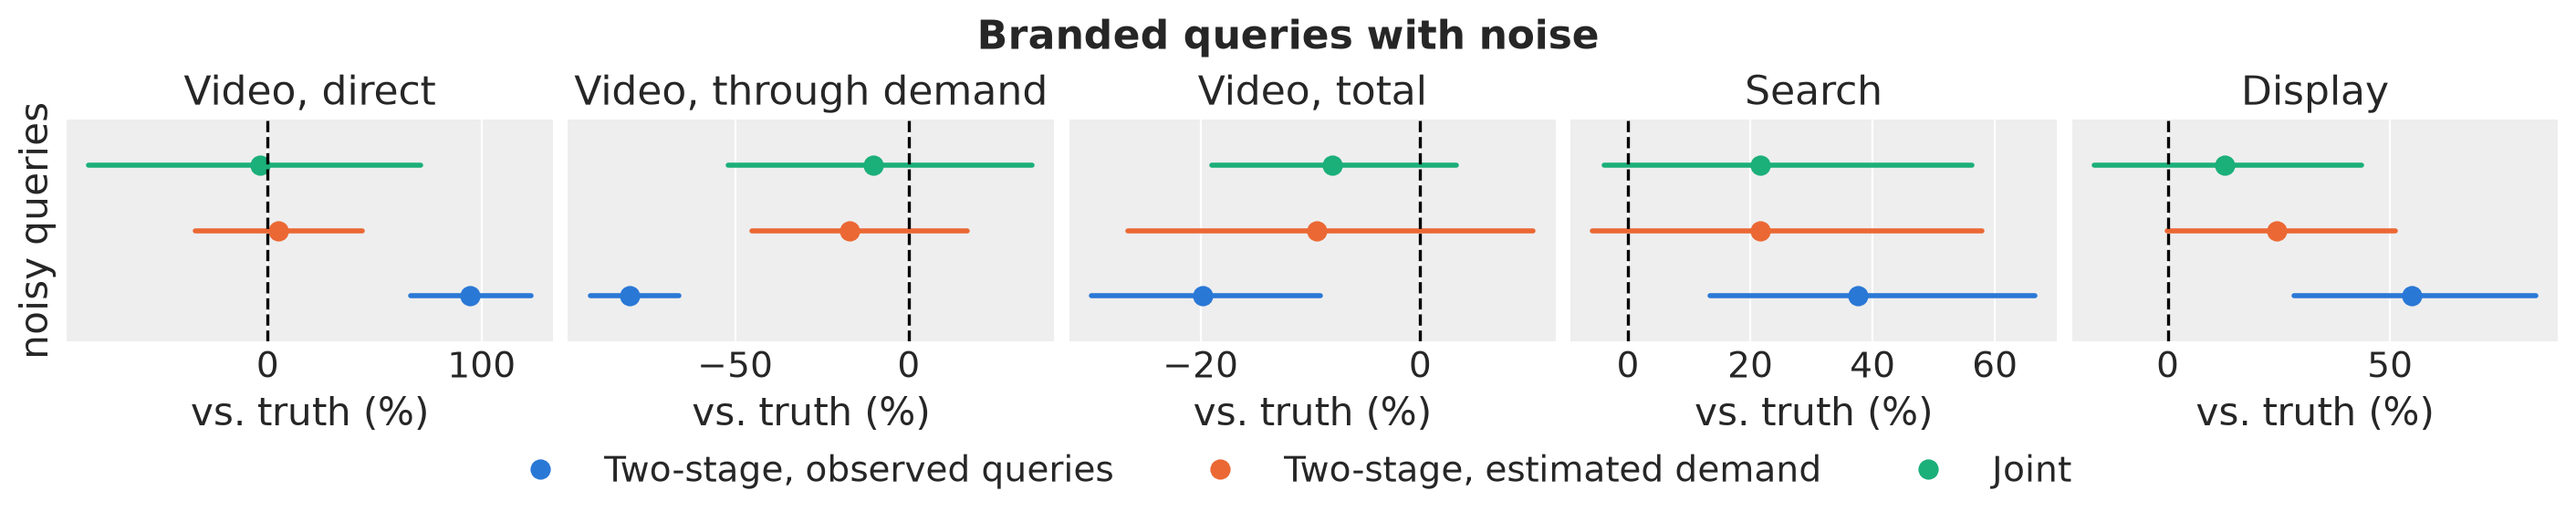

In [24]:
effects_noisy, decisions_noisy = evaluate(
    {
        "Two-stage, observed queries": (observed_noisy.idata, stage1_noisy),
        "Two-stage, estimated demand": (estimated_noisy.idata, stage1_noisy),
        "Joint": (joint_noisy.idata, joint_noisy.idata),
    },
    world,
)
summary_noisy = summarize(effects_noisy, truth)
plot_recovery({"noisy queries": summary_noisy}, "Branded queries with noise");

**Caption:** Each model's estimate relative to the truth (dashed line at 0%). Dots are posterior means; bars are 94% intervals.

In [25]:
format_summary(summary_noisy)

In [26]:
format_decisions(decisions_noisy)

,correlation,video share,search share,display share,budget loss
model,,,,,
"Two-stage, observed queries",+0.01,28%,52%,20%,-5.7%
"Two-stage, estimated demand",+0.03,42%,36%,22%,-0.7%
Joint,-0.33,40%,40%,20%,-1.4%


Treating the noisy series as demand goes wrong: noise in a regressor pulls its estimated effect toward zero. The observed-queries model understates video's effect through mediated demand by 80% and hands the difference to the direct effect. None of its intervals contains the truth. A noisy query series is also a weak control for search and display in stage 2, as they absorb part of it and are over-credited.

In this world, the two models that estimate demand from the queries both do well, and their intervals contain the truth for all five effects. The joint model's intervals for video's split are wider, which reflects how little the noisy queries say about demand. Estimated demand gives the slightly better budget here. The replications below show which pattern is typical.

The joint model's cross-stage correlation is −0.33: in draws where video lifts demand more, its direct effect is smaller. Conversions pin down the sum of the two paths, and the joint model has learned how they trade off. In the two-stage models the correlation is zero by construction.

The joint model does not need the grid search. Its demand path is a mu effect that reads video spend from the model, so {class}`~pymc_marketing.mmm.budget_optimizer.BudgetOptimizer` can optimize it directly, once the objective counts that path: `response_variable="total_response_original_scale"` includes the mu effects, while the default objective counts the channel contributions only. We optimize over the training window, where the effect has the organic interest and branded queries it was fit on, and compare the result with the grid's best plan. A two-stage model has no such graph, so its response has to be chained by hand, as `media_response` does.

In [27]:
def optimize_with_library(mmm, world):
    """Best weekly split under a fitted joint model, from BudgetOptimizer.

    The window is the training range, so the effect reads the same dates, organic
    interest, and branded queries as in the fit.
    """
    dates = mmm.model.coords["date"]
    lags = mmm.effective_carryover_lags()
    opt_model = mmm.create_optimization_model(
        start_date=dates[0], end_date=dates[-(lags + 1)]
    )
    budget = float(world[CHANNELS].mean().sum())
    optimizer = BudgetOptimizer(
        model=opt_model,
        idata=mmm.idata,
        num_periods=len(dates),
        adstock_periods=0,
        response_variable="total_response_original_scale",
        # The default backend cannot compile the gradient of the chained adstock.
        compile_kwargs={"mode": Mode(linker="cvm")},
    )
    bounds = xr.DataArray(
        np.tile([0.0, budget], (len(CHANNELS), 1)),
        dims=["channel", "bound"],
        coords={"channel": CHANNELS, "bound": ["lower", "upper"]},
    )
    result = optimizer.allocate_budget(total_budget=budget, budget_bounds=bounds)
    return result.budgets.sel(channel=CHANNELS).to_numpy()


plans = plan_grid(world)
best = true_best(plans, world)
joint_plans = {
    "BudgetOptimizer": optimize_with_library(joint_noisy, world),
    "Grid search": best_plan(joint_noisy.idata, joint_noisy.idata, plans),
}
pd.DataFrame(
    {
        label: {
            **{
                f"{c} share": s
                for c, s in zip(CHANNELS, plan / plan.sum(), strict=True)
            },
            "budget loss": plan_loss(plan, world, best),
        }
        for label, plan in joint_plans.items()
    }
).T.style.format(
    {**{f"{c} share": "{:.0%}" for c in CHANNELS}, "budget loss": "{:+.1%}"}
)

,video share,search share,display share,budget loss
BudgetOptimizer,40%,40%,20%,-1.5%
Grid search,40%,40%,20%,-1.4%


The two plans give the same split to the nearest percentage point and lose about the same share of conversions, so the grid search is a faithful stand-in for the optimizer in the comparisons that follow.

### Replications

One world shows whether an interval happened to contain the truth, not how often it does. We repeat the comparison in 50 new worlds. The first table reports, per path and model:

- **coverage**, the share of 94% intervals that contain the true effect, with its standard error;
- **mean bias**, the average error relative to the truth;
- **typical error**, the root mean square of that error, which is how far the estimate usually lands from the truth;
- **claimed error**, the error that the model's own interval implies.

When typical and claimed error match, the interval is calibrated; a claimed error below the typical error means the model is overconfident. The standard error of a coverage figure depends on the coverage itself: about 3 percentage points at 94% and about 7 points at 50%.

The second table reports the cross-stage correlation and the budget loss, on average and in the worst world. The last table counts the fits with divergences, an r-hat above 1.01, or a bulk ESS below 400.

In [28]:
n_reps = 50
fast = {"tune": 1_000, "draws": 500}


def replicate_noisy(rep):
    """One replication of the noisy-query comparison in a new synthetic world."""
    rng_r = rng_for(20, rep)
    world_r, truth_r = simulate_world(rng_r)
    frame = measure_queries(world_r, sigma=query_noise, rng=rng_r)
    stage1 = fit_stage1(frame, basis, rng_r, **fast)
    frame = frame.assign(queries_estimated=flat(stage1, "query_latent").mean(axis=0))
    observed = fit_stage2(frame, "branded_queries", rng_r, **fast)
    estimated = fit_stage2(frame, "queries_estimated", rng_r, **fast)
    joint = fit_joint(frame, rng_r, **fast)
    effects, decisions = evaluate(
        {
            "Two-stage, observed queries": (observed.idata, stage1),
            "Two-stage, estimated demand": (estimated.idata, stage1),
            "Joint": (joint.idata, joint.idata),
        },
        world_r,
    )
    fits = {
        "stage 1": stage1,
        "stage 2, observed queries": observed.idata,
        "stage 2, estimated demand": estimated.idata,
        "joint": joint.idata,
    }
    return summarize(effects, truth_r), decisions.reset_index(), diagnostics(fits)


def collect(results):
    """Stack the replications' recovery, decision, and diagnostics tables."""
    summaries, decisions, fit_diagnostics = zip(*results, strict=True)
    return (
        pd.concat(
            [s.assign(rep=r) for r, s in enumerate(summaries)], ignore_index=True
        ),
        pd.concat(
            [d.assign(rep=r) for r, d in enumerate(decisions)], ignore_index=True
        ),
        pd.concat(fit_diagnostics),
    )


replications_noisy, decisions_noisy_reps, diagnostics_noisy_reps = collect(
    [replicate_noisy(rep) for rep in range(n_reps)]
)

In [29]:
coverage_table(replications_noisy)

In [30]:
decision_summary(decisions_noisy_reps)

,mean_correlation,mean_budget_loss,worst_budget_loss
model,,,
"Two-stage, observed queries",+0.00,-4.4%,-21.8%
"Two-stage, estimated demand",+0.00,-2.5%,-14.4%
Joint,-0.33,-1.5%,-8.6%


In [33]:
flag_fits(diagnostics_noisy_reps)

,fits,with divergences,r_hat > 1.01,ess_bulk < 400
stage 1,50,0,11,24
"stage 2, observed queries",50,1,23,45
"stage 2, estimated demand",50,0,19,43
joint,50,0,23,43


Using the noisy series as if it were demand fails in every world. Video's split is wrong in the same direction each time, with too much credit on the direct path and too little through demand, and the intervals never contain the truth. Search and display are over-credited too.

Estimating demand removes most of that bias, in either strategy, but the two still differ:

- **Accuracy:** the joint model has the smaller typical error on all five paths.
- **Uncertainty:** the joint model's claimed error is close to its typical error on most paths, and its intervals contain the truth in at least 88% of worlds. The two-stage intervals for video's split claim between half and two thirds of their real error, and contain the truth less often. The exception is video's total, where the two-stage interval covers more often: it is a little wider than its error, while the joint model's is centered slightly low.
- **Budget:** the joint model's plans lose the fewest conversions, on average and in the worst world: 1.5% of media-driven conversions on average, against 2.5% for estimated demand and 4.4% for observed queries.

The two-stage intervals are too narrow because stage 2 treats stage 1's best guess of demand as if it were known. The joint model carries that uncertainty through, lets conversions inform demand, and keeps the trade-off between video's two paths.

The replication fits use a shorter sampler run, so their numbers carry more Monte Carlo error than the single-world fits.

## Layer 3: the sales equation misses a driver

Letting conversions inform demand is what helps the joint model in layer 2, and it is also how the joint model can go wrong. If the sales equation misses something, the joint model can explain the gap by moving demand, and the error spreads into the demand equation. Stage 1 of a two-stage fit never sees conversions, so there the error stays in stage 2.

To test it, we add a driver that no model includes: a temporary price cut that raises conversions by 0.15 (about 8% of weekly conversions) for 8 weeks, at a random time independent of the media. Both strategies see the same demand spline: two-stage through its estimated demand series, which conversions cannot change, and the joint model through a demand that conversions can move. A step this short, with sharp edges, is finer than the spline can follow (its knots are about 14 weeks apart), so moving demand can absorb only part of it.

Branded queries carry the same noise as in layer 2. With exact queries the joint model can use the observed series, and the factorization above then makes the two strategies coincide whatever the sales equation leaves out. We compare the estimated-demand two-stage model with the joint model.

In [34]:
def add_unmodeled_driver(world, rng, height=0.15, length=8):
    """Add a temporary price cut: conversions step up by ``height`` for ``length`` weeks.

    No model includes it, and its timing is drawn independently of the media.
    """
    start = rng.integers(20, N_WEEKS - 20 - length + 1)
    step = np.zeros(N_WEEKS)
    step[start : start + length] = height
    return world.assign(conversions=world["conversions"] + step), start


def fit_unmodeled(frame, basis, world, rng, **kwargs):
    """Fit the estimated-demand two-stage model and the joint model, then evaluate both."""
    stage1 = fit_stage1(frame, basis, rng, **kwargs)
    frame = frame.assign(queries_estimated=flat(stage1, "query_latent").mean(axis=0))
    estimated = fit_stage2(frame, "queries_estimated", rng, **kwargs)
    joint = fit_joint(frame, rng, **kwargs)
    effects, decisions = evaluate(
        {
            "Two-stage, estimated demand": (estimated.idata, stage1),
            "Joint": (joint.idata, joint.idata),
        },
        world,
    )
    fits = {"stage 1": stage1, "stage 2": estimated.idata, "joint": joint.idata}
    return effects, decisions, fits


rng_layer3 = rng_for(3)
world_cut, cut_start = add_unmodeled_driver(world, rng_layer3)
effects_cut, decisions_cut, fits_cut = fit_unmodeled(
    measure_queries(world_cut, sigma=query_noise, rng=rng_layer3),
    basis,
    world,
    rng_layer3,
)

In [35]:
diagnostics(fits_cut)

,divergences,max r_hat,min ess_bulk
stage 1,0.0,1.01,511.0
stage 2,0.0,1.01,772.0
joint,0.0,1.01,712.0


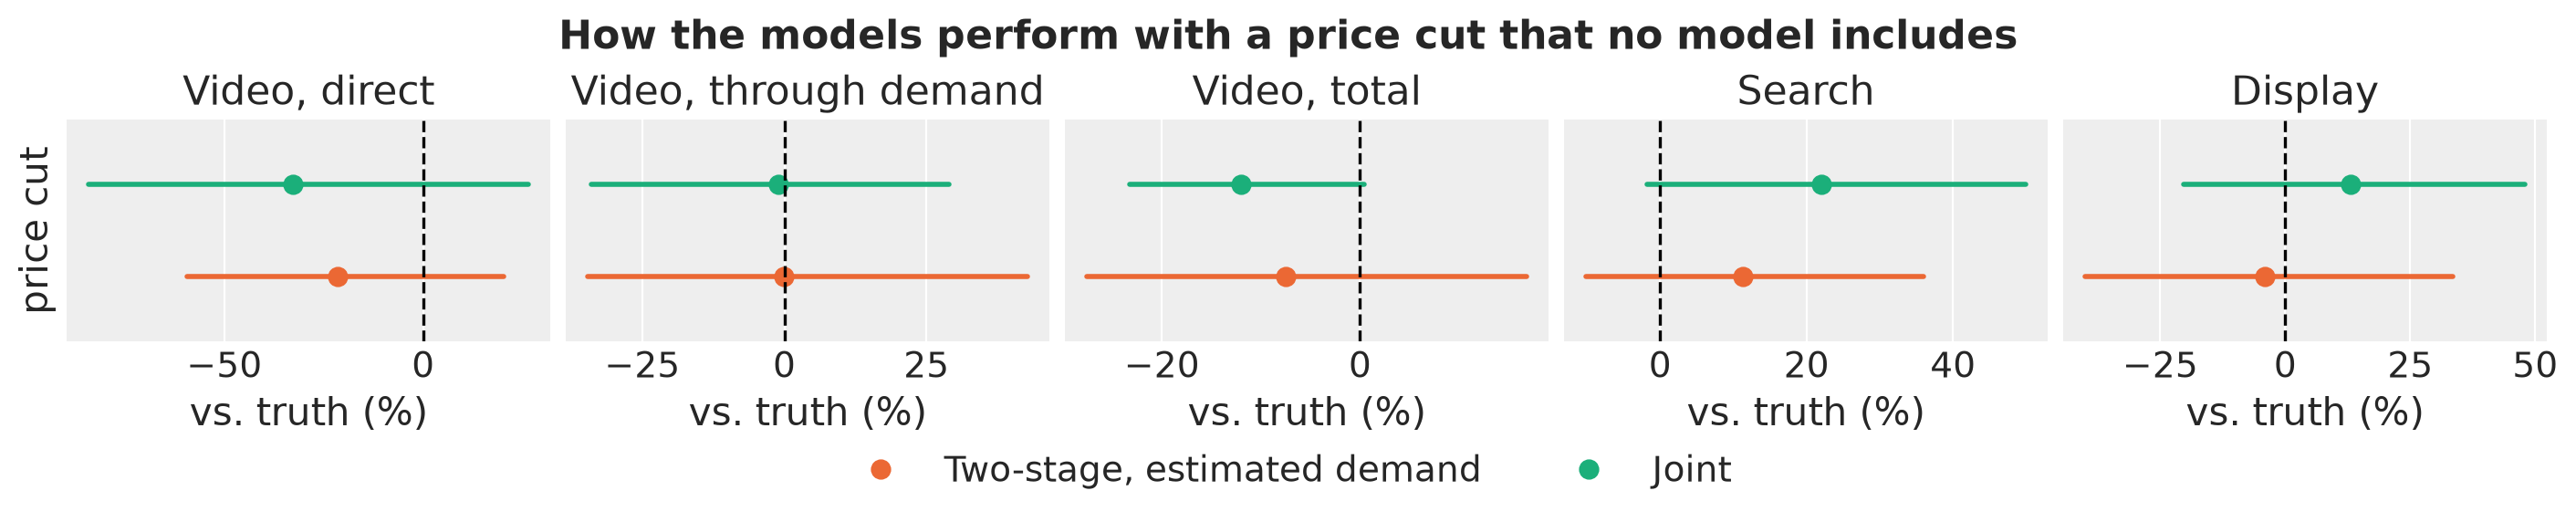

In [36]:
summary_cut = summarize(effects_cut, truth)
plot_recovery(
    {"price cut": summary_cut},
    "How the models perform with a price cut that no model includes",
);

In [37]:
format_summary(summary_cut)

In [38]:
format_decisions(decisions_cut)

,correlation,video share,search share,display share,budget loss
model,,,,,
"Two-stage, estimated demand",+0.02,42%,42%,16%,-2.3%
Joint,-0.09,36%,46%,18%,-3.0%


In this world, both models get video's effect through demand about right and understate its direct effect, the joint model more so. All their intervals contain the truth. The joint model is further off on video's total, search, and display, and its plan loses slightly more conversions. Differences this small in one world could be chance; the replications below test them.

In [39]:
def replicate_unmodeled(rep):
    """One replication with a new world and a new timing of the price cut."""
    rng_r = rng_for(30, rep)
    world_r, truth_r = simulate_world(rng_r)
    world_cut_r, _ = add_unmodeled_driver(world_r, rng_r)
    effects, decisions, fits = fit_unmodeled(
        measure_queries(world_cut_r, sigma=query_noise, rng=rng_r),
        basis,
        world_r,
        rng_r,
        **fast,
    )
    return summarize(effects, truth_r), decisions.reset_index(), diagnostics(fits)


replications_unmodeled, decisions_unmodeled_reps, diagnostics_unmodeled_reps = collect(
    [replicate_unmodeled(rep) for rep in range(n_reps)]
)

In [40]:
coverage_table(replications_unmodeled)

In [41]:
decision_summary(decisions_unmodeled_reps)

,mean_correlation,mean_budget_loss,worst_budget_loss
model,,,
"Two-stage, estimated demand",+0.01,-4.5%,-28.2%
Joint,-0.22,-2.1%,-11.4%


In [44]:
flag_fits(diagnostics_unmodeled_reps)

,fits,with divergences,r_hat > 1.01,ess_bulk < 400
stage 1,50,0,8,19
stage 2,50,0,22,45
joint,50,1,20,36


Across 50 worlds, each with the price cut at a different time, the joint model shifts video's credit toward the path through demand, because its estimate of demand absorbs part of the price cut. Its intervals still contain the truth in 90% of worlds for both paths. The two-stage model shifts the split less, but its intervals are too narrow and contain the truth less often. Neither is clearly more accurate on the split: the joint model has the larger typical error on the direct effect and the smaller one through demand.

Everywhere else, the joint model holds up better. It has the smaller typical error on video's total, search, and display. Two-stage over-credits search, and its search intervals contain the truth much less often. Video's two paths saturate at different rates, so the budget depends on the split as well as on the total. Even so, the joint model's plans lose fewer conversions: 2.1% of media-driven conversions on average against 4.5% for two-stage, and less than half as much in the worst world.

A missing sales driver makes the split of video's effect unreliable in either strategy. Checking the sales equation, for example with residual plots and posterior predictive checks, matters before reporting the split.

## Conclusions

**When the model is well specified, the joint model appears to be a superior choice.** With exact queries, the two strategies give the same answers, so the choice does not matter. When queries are a noisy proxy, the joint model was more accurate than the best two-stage setup, reported its uncertainty more reliably, and led to budgets that lost fewer conversions.

The condition matters because the joint model's strength and its risk are the same mechanism. Conversions inform demand, and so a gap in the sales equation reaches the demand equation. When the sales equation missed a driver, the joint model's budgets still lost fewer conversions, but its estimate of demand absorbed part of the missing driver and shifted video's credit toward the path through demand. Neither strategy split video's effect reliably in that case.

These results come from a deliberately noisy setting: we chose the query noise so that the differences show. With more accurate queries the strategies move closer, and with exact queries they coincide. The noise is also independent and Gaussian, the easiest case for a model with smooth latent demand. Real branded-query error is often systematic, from navigational searches by existing customers, seasonal search habits, or a brand name that is also a common word, and it can be correlated with conversions. We have not simulated that case, which tests the measurement side of the joint model, nor a price cut that coincides with a campaign, which would confound the missing driver with video.

A few practical points hold whichever strategy you choose:

- **Estimate demand** rather than feeding raw branded queries into the sales equation. Most of the error in this notebook comes from that shortcut.
- **Make sure the budget optimizer sees the whole path** from upper-funnel media through demand to sales. A joint model has it built in; with two-stage, it has to be chained by hand.
- **Check the sales equation** before reporting how an upper-funnel channel's effect splits between its direct and indirect paths. A missing sales driver biased the joint model's split and made the two-stage intervals too narrow.

These conclusions come from one synthetic market with three channels, the true transformation families, and 50 replications per layer. For a funnel on real data, with a spend lever and calibration against experiments, see {ref}`mmm_case_study2`. For a mediator read by several indicators at geo level, see {ref}`mmm_funnel_mueffect_advanced`. Branded queries leave some confounding in place; experiments such as lift tests can calibrate the affected effects, as shown in {ref}`mmm_roas` and {ref}`mmm_lift_test`.

In [45]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Fri, 23 Oct 2026

Python implementation: CPython
Python version       : 3.12.15
IPython version      : 9.15.0

pymc_marketing: 1.3.0
pytensor      : 3.3.2

arviz         : 1.2.0
logging       : 0.5.1.2
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pydantic      : 2.13.4
pymc          : 6.3.2
pymc_marketing: 1.3.0
pytensor      : 3.3.2
scipy         : 1.15.3
xarray        : 2026.4.0

Watermark: 2.6.0

